<a href="https://colab.research.google.com/github/Arg26/IBM-Project-Sem-7/blob/main/Fashion_MNIST_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fashion-MNIST Image Classifier 👕👟
Train a neural network to classify the 10 Fashion-MNIST clothing categories.

**A quick reality check:** no model can guarantee perfect accuracy on unseen images. This notebook uses a strong CNN baseline, validation-based checkpointing, and an untouched test set so you can measure genuine performance without data leakage.

**Expected files:** `fashion-mnist_train.csv` and `fashion-mnist_test.csv` in the same folder as this notebook. Each row contains a label followed by 784 pixel values (28×28 grayscale image).

## 1. Install / import dependencies
If TensorFlow is not installed, uncomment and run the install command. In Google Colab, TensorFlow is often already available.

In [ ]:
!pip install -q tensorflow pandas numpy matplotlib scikit-learn

In [ ]:
# If needed, run this once:
# %pip install -q tensorflow pandas numpy matplotlib scikit-learn

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load and inspect the CSV files
Change the paths below if your CSV files are stored somewhere else.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import os
import pandas as pd

# Your Google Drive project directory
PROJECT_DIR = "/content/drive/MyDrive/ibm project"
DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")

# Check where the CSV files are stored
print("Project files:", os.listdir(PROJECT_DIR))
print("Dataset files:", os.listdir(DATASET_DIR))

# Update these paths if your CSV files are in the project root instead
TRAIN_CSV = os.path.join(DATASET_DIR, "fashion-mnist_train.csv")
TEST_CSV = os.path.join(DATASET_DIR, "fashion-mnist_test.csv")

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Training CSV shape:", train_df.shape)
print("Test CSV shape:", test_df.shape)

display(train_df.head())


Project files: ['dataset', 'Fashion_MNIST_Training.ipynb']
Dataset files: ['fashion-mnist_test.csv', 'fashion-mnist_train.csv', 't10k-images-idx3-ubyte', 't10k-labels-idx1-ubyte', 'train-images-idx3-ubyte', 'train-labels-idx1-ubyte']
Training CSV shape: (60000, 785)
Test CSV shape: (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Fashion-MNIST labels are 0–9; CSV format is label + 784 pixels.
assert train_df.shape[1] == 785, f"Expected 785 columns, got {train_df.shape[1]}"
assert test_df.shape[1] == 785, f"Expected 785 columns, got {test_df.shape[1]}"

LABEL_COL = "label" if "label" in train_df.columns else train_df.columns[0]
pixel_cols = [c for c in train_df.columns if c != LABEL_COL]
if len(pixel_cols) != 784:
    LABEL_COL = train_df.columns[0]
    pixel_cols = list(train_df.columns[1:])

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

y_all = train_df[LABEL_COL].to_numpy(dtype=np.int64)
X_all = train_df[pixel_cols].to_numpy(dtype=np.float32).reshape(-1, 28, 28, 1) / 255.0
y_test = test_df[LABEL_COL].to_numpy(dtype=np.int64)
X_test = test_df[pixel_cols].to_numpy(dtype=np.float32).reshape(-1, 28, 28, 1) / 255.0

print("Training images:", X_all.shape, "Labels:", y_all.shape)
print("Test images:", X_test.shape, "Labels:", y_test.shape)
print("Labels present:", np.unique(y_all))

Training images: (60000, 28, 28, 1) Labels: (60000,)
Test images: (10000, 28, 28, 1) Labels: (10000,)
Labels present: [0 1 2 3 4 5 6 7 8 9]


## 3. Visualize a few training examples

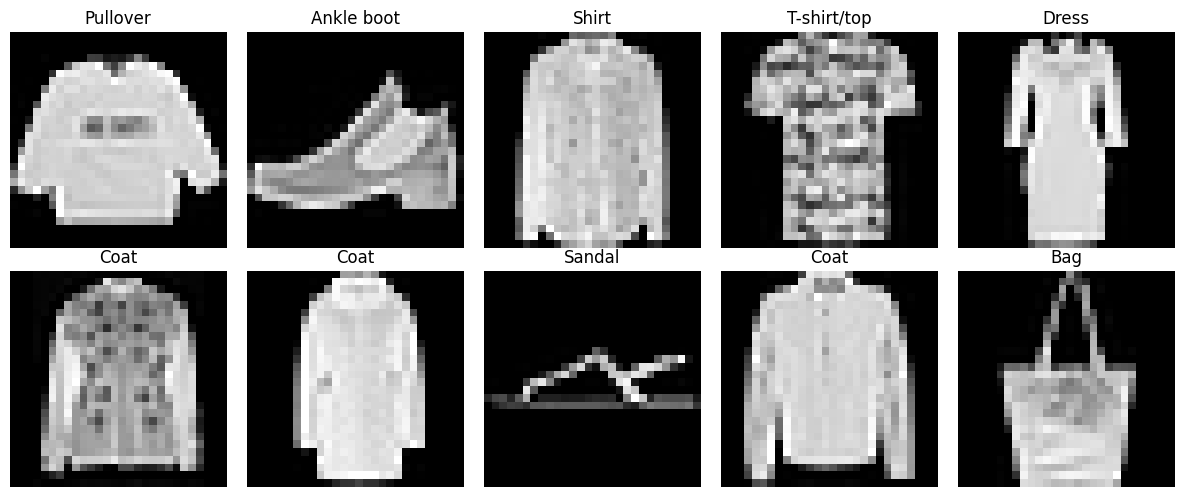

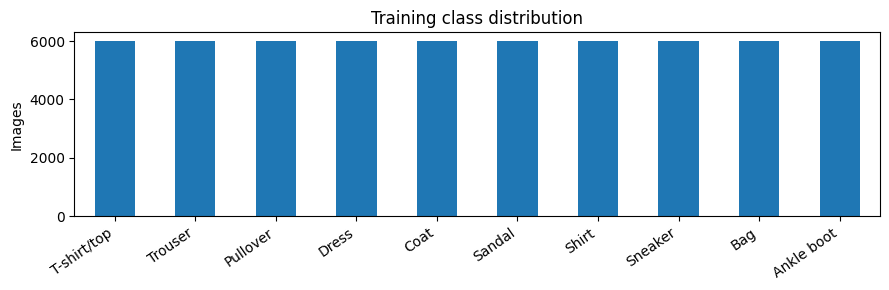

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_all[i].squeeze(), cmap="gray")
    ax.set_title(class_names[y_all[i]])
    ax.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 3))
pd.Series(y_all).value_counts().sort_index().plot(kind="bar")
plt.xticks(range(10), class_names, rotation=35, ha="right")
plt.ylabel("Images")
plt.title("Training class distribution")
plt.tight_layout()
plt.show()

## 4. Create a stratified train/validation split
The supplied training CSV is split into training and validation subsets. The supplied test CSV is kept untouched until final evaluation.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all,
    test_size=0.10,
    random_state=SEED,
    stratify=y_all
)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

Train: (54000, 28, 28, 1) Validation: (6000, 28, 28, 1) Test: (10000, 28, 28, 1)


## 5. Build a convolutional neural network
Convolutions learn local visual patterns such as edges and clothing shapes. Batch normalization and dropout help regularize the model.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def build_model():
    inputs = keras.Input(shape=(28, 28, 1))

    x = layers.RandomTranslation(0.08, 0.08)(inputs)
    x = layers.RandomRotation(0.06)(x)
    x = layers.RandomZoom(0.08)(x)

    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.20)(x)

    x = layers.Conv2D(64, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(64, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(128, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.35)(x)

    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="fashion_mnist_cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

model = build_model()
model.summary()

Model: "fashion_mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           51

 Total params: 157,610 (615.66 KB)

 Trainable params: 156,970 (613.16 KB)

 Non-trainable params: 640 (2.50 KB)

## 6. Train with callbacks
The best model is saved based on validation accuracy. Early stopping reduces unnecessary training if validation performance stops improving.

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

checkpoint_path = "best_fashion_mnist.keras"
callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

# Load the best validation checkpoint if it was saved.
if os.path.exists(checkpoint_path):
    model = keras.models.load_model(checkpoint_path)

Epoch 1/40
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6088 - loss: 1.0620
Epoch 1: val_accuracy improved from None to 0.22867, saving model to best_fashion_mnist.keras

Epoch 1: finished saving model to best_fashion_mnist.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 24ms/step - accuracy: 0.7075 - loss: 0.7892 - val_accuracy: 0.2287 - val_loss: 3.2845 - learning_rate: 0.0010
Epoch 2/40
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7990 - loss: 0.5467
Epoch 2: val_accuracy improved from 0.22867 to 0.83350, saving model to best_fashion_mnist.keras

Epoch 2: finished saving model to best_fashion_mnist.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.8044 - loss: 0.5312 - val_accuracy: 0.8335 - val_loss: 0.4754 - learning_rate: 0.0010
Epoch 3/40
421/422 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8231 - loss: 0.4841
Epoch 3: val_accuracy improved from 0.83350 to 0.84067, saving model to best_fashion_mnist.keras

Epoch 3: finished saving model to best_fashi

## 7. Plot learning curves

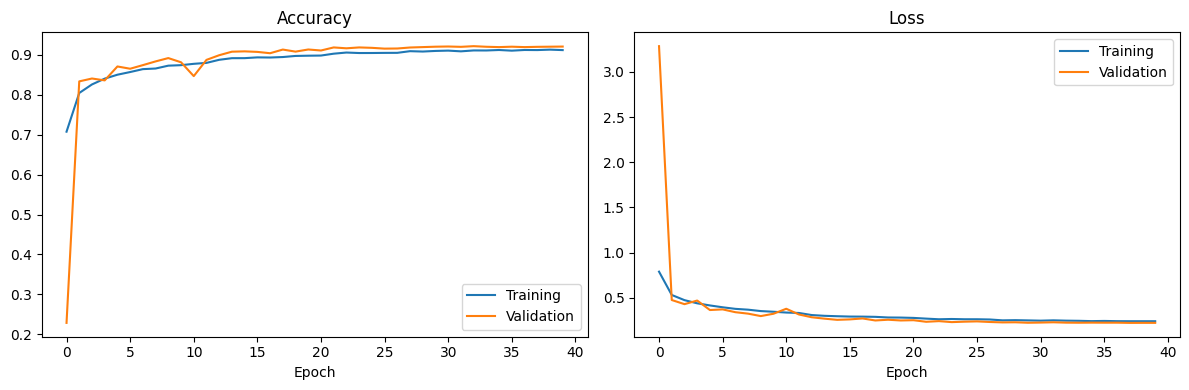

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

## 8. Evaluate once on the held-out test set
This is the honest estimate of how the trained model performs on unseen examples. Accuracy below 100% is normal for Fashion-MNIST.

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4%}")
print(f"Test loss:     {test_loss:.4f}")

Test accuracy: 92.2900%
Test loss:     0.2098


              precision    recall  f1-score   support

 T-shirt/top     0.9041    0.8300    0.8655      1000
     Trouser     0.9930    0.9870    0.9900      1000
    Pullover     0.9323    0.8670    0.8984      1000
       Dress     0.9250    0.9380    0.9315      1000
        Coat     0.8842    0.8930    0.8886      1000
      Sandal     0.9839    0.9760    0.9799      1000
       Shirt     0.7232    0.8150    0.7663      1000
     Sneaker     0.9464    0.9720    0.9591      1000
         Bag     0.9861    0.9920    0.9890      1000
  Ankle boot     0.9766    0.9590    0.9677      1000

    accuracy                         0.9229     10000
   macro avg     0.9255    0.9229    0.9236     10000
weighted avg     0.9255    0.9229    0.9236     10000



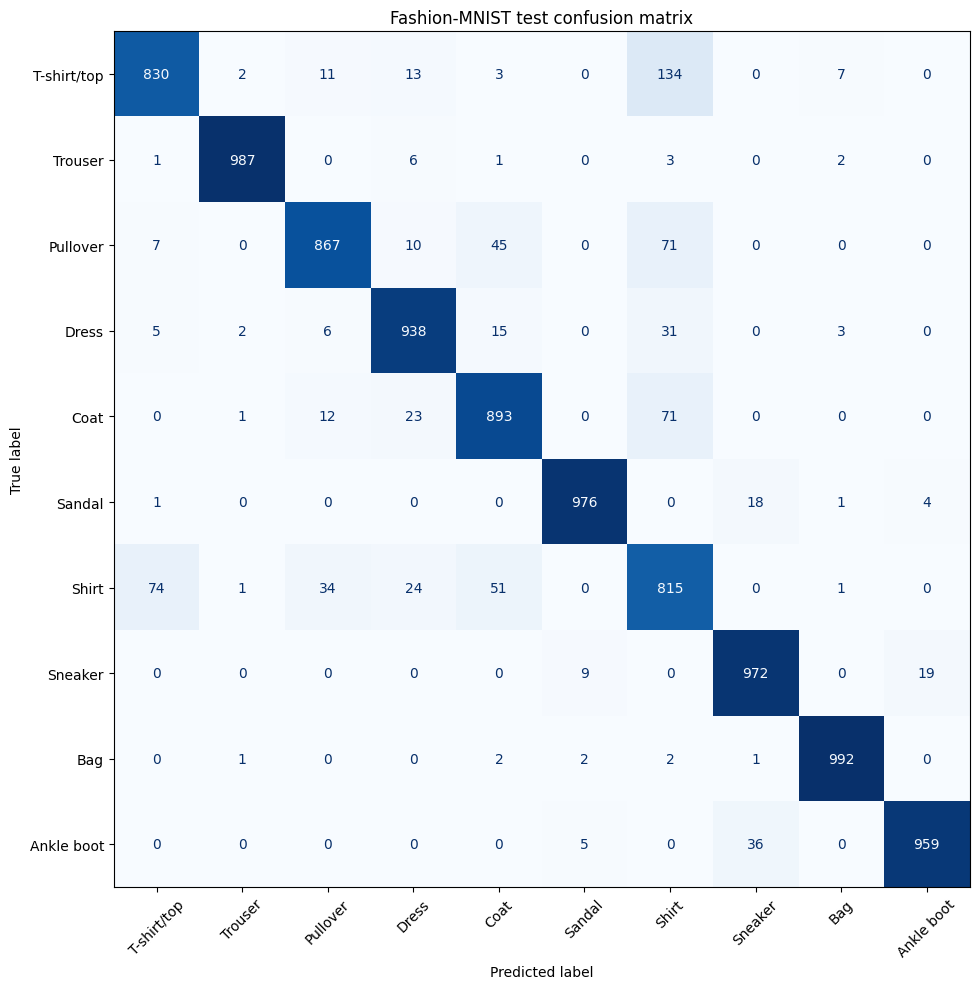

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

probabilities = model.predict(X_test, batch_size=256, verbose=0)
y_pred = probabilities.argmax(axis=1)

print(classification_report(y_test, y_pred, target_names=class_names, digits=4))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Fashion-MNIST test confusion matrix")
plt.tight_layout()
plt.show()

## 9. Inspect incorrect predictions

Incorrect predictions: 771 / 10000


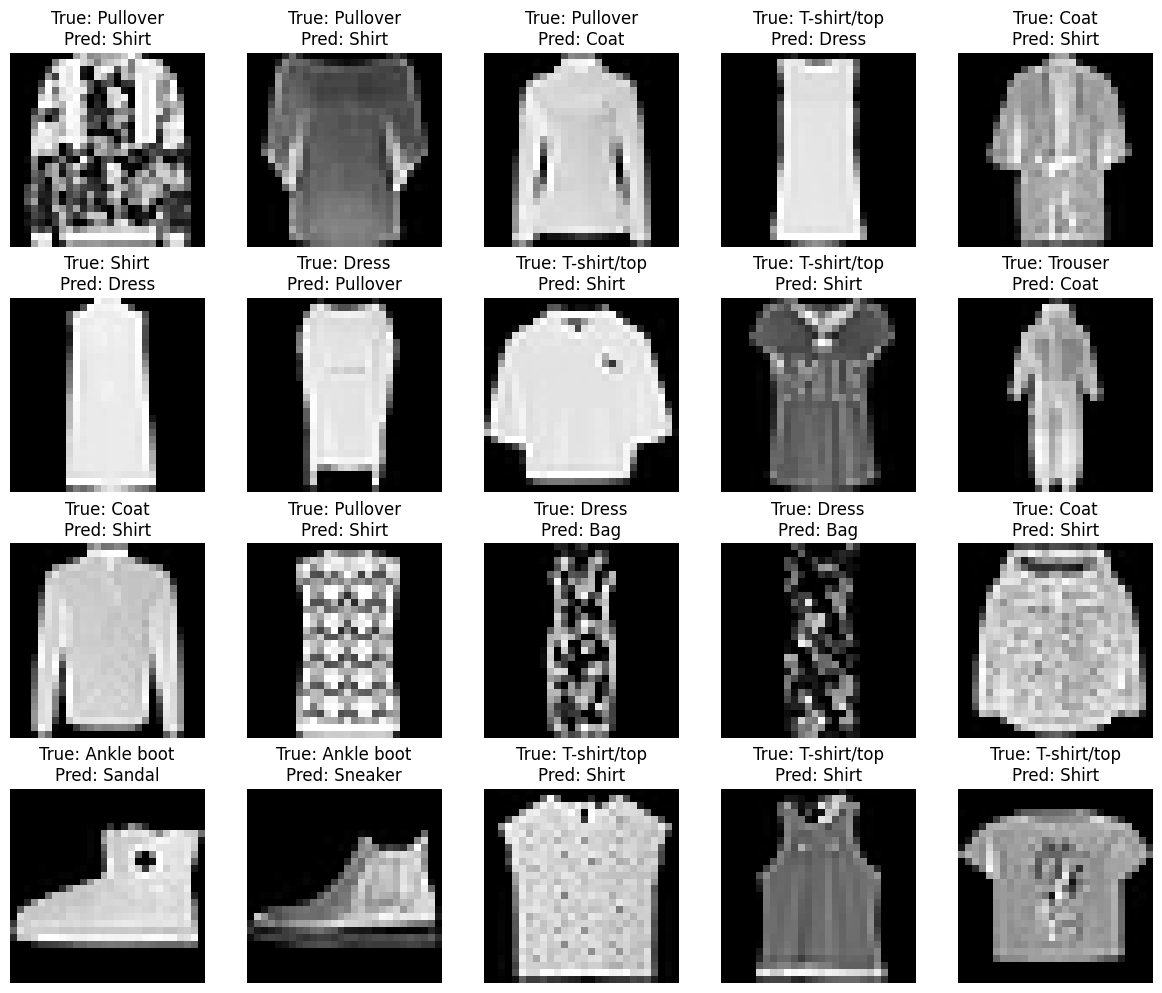

In [ ]:
wrong = np.flatnonzero(y_pred != y_test)
print(f"Incorrect predictions: {len(wrong)} / {len(y_test)}")

if len(wrong):
    n = min(20, len(wrong))
    fig, axes = plt.subplots(4, 5, figsize=(12, 10))
    for ax, idx in zip(axes.flat, wrong[:n]):
        ax.imshow(X_test[idx].squeeze(), cmap="gray")
        ax.set_title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}")
        ax.axis("off")
    for ax in axes.flat[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No mistakes on this test split. Verify the test data is independent and correctly formatted.")

## 10. Save the trained model and make a prediction
The saved `.keras` file can be loaded later without retraining.

In [ ]:

model.save("fashion_mnist_classifier.keras")
print("Saved: fashion_mnist_classifier.keras")

def predict_image(image_28x28):
    """Predict a single 28x28 grayscale image."""
    image = np.asarray(image_28x28, dtype=np.float32)

    if image.max() > 1.0:
        image = image / 255.0

    image = image.reshape(1, 28, 28, 1)
    probs = model.predict(image, verbose=0)[0]
    idx = int(np.argmax(probs))

    return class_names[idx], float(probs[idx])


# Predict the first test image
predicted_class, confidence = predict_image(X_test[0])

print("Predicted:", predicted_class)
print("Confidence:", f"{confidence:.2%}")
print("Actual:", class_names[int(y_test[0])])


Saved: fashion_mnist_classifier.keras
Predicted: T-shirt/top
Confidence: 98.54%
Actual: T-shirt/top


## Optional: If you want to improve further
- Train longer only if validation accuracy is still improving.
- Try a slightly wider/deeper CNN and compare validation results.
- Keep the test set untouched while tuning.
- Do not optimize by repeatedly checking test accuracy; that causes test-set leakage.
- “Perfect accuracy” cannot be promised on this dataset because some clothing classes are visually ambiguous.

Saving 000000004395.jpg to 000000004395.jpg
Predicted clothing: T-shirt/top
Model confidence: 59.72%


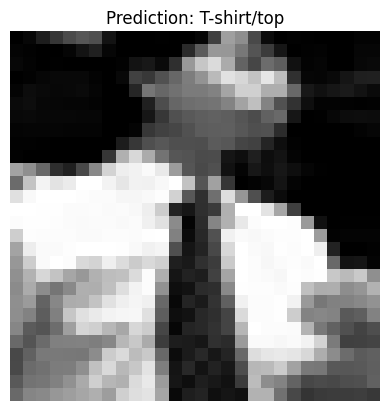

In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Upload your own image
uploaded = files.upload()

# Get the uploaded filename
filename = next(iter(uploaded))

# Load and preprocess the image
img = Image.open(filename).convert("L")
img = img.resize((28, 28))

image_array = np.array(img, dtype=np.float32) / 255.0

# Fashion-MNIST uses white clothing on a black background.
# Typical photos have the opposite, so invert if needed.
if image_array.mean() > 0.5:
    image_array = 1.0 - image_array

# Prepare image for the CNN
image_input = image_array.reshape(1, 28, 28, 1)

# Predict
probabilities = model.predict(image_input, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))

print("Predicted clothing:", class_names[predicted_index])
print(f"Model confidence: {probabilities[predicted_index]:.2%}")

# Display the processed image
plt.imshow(image_array, cmap="gray")
plt.title(f"Prediction: {class_names[predicted_index]}")
plt.axis("off")
plt.show()
